In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [2]:
df = pd.read_csv("emails.csv")

df.head()

,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


In [3]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nFirst Five Records:")
print(df.head())

Dataset Shape: (5172, 3002)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 5172 entries, 0 to 5171
Columns: 3002 entries, Email No. to Prediction
dtypes: int64(3001), str(1)
memory usage: 118.5 MB

Missing Values:
0

First Five Records:
  Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  jay  \
0   Email 1    0   0    1    0    0   0    2    0    0  ...         0    0   
1   Email 2    8  13   24    6    6   2  102    1   27  ...         0    0   
2   Email 3    0   0    1    0    0   0    8    0    0  ...         0    0   
3   Email 4    0   5   22    0    5   1   51    2   10  ...         0    0   
4   Email 5    7   6   17    1    5   2   57    0    9  ...         0    0   

   valued  lay  infrastructure  military  allowing  ff  dry  Prediction  
0       0    0               0         0         0   0    0           0  
1       0    0               0         0         0   1    0           0  
2       0    0               0         0         0   0    

In [4]:
# Remove the first column (email identifier)
df = df.iloc[:, 1:]

# Remove missing values
df = df.dropna()

# Separate input features and target
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

# Convert target labels into numerical values if required
if y.dtype == 'object':
    encoder = LabelEncoder()
    y = encoder.fit_transform(y)

print("Input Shape:", X.shape)
print("Target Shape:", y.shape)

Input Shape: (5172, 3000)
Target Shape: (5172,)


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (4137, 3000)
Testing Data: (1035, 3000)


In [6]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Feature Scaling Completed")

Feature Scaling Completed


In [7]:
knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train, y_train)

knn_predictions = knn_model.predict(X_test)

print("KNN Classification Completed")

KNN Classification Completed


In [8]:
print("KNN Results")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, knn_predictions))

print("\nAccuracy:", accuracy_score(y_test, knn_predictions))

print("Precision:", precision_score(
    y_test, knn_predictions, zero_division=0
))

print("Recall:", recall_score(
    y_test, knn_predictions, zero_division=0
))

print("F1 Score:", f1_score(
    y_test, knn_predictions, zero_division=0
))

KNN Results

Confusion Matrix:
[[576 159]
 [ 13 287]]

Accuracy: 0.8338164251207729
Precision: 0.6434977578475336
Recall: 0.9566666666666667
F1 Score: 0.7694369973190348


In [9]:
svm_model = SVC(kernel='linear')

svm_model.fit(X_train, y_train)

svm_predictions = svm_model.predict(X_test)

print("SVM Classification Completed")

SVM Classification Completed


In [10]:
print("SVM Results")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, svm_predictions))

print("\nAccuracy:", accuracy_score(y_test, svm_predictions))

print("Precision:", precision_score(
    y_test, svm_predictions, zero_division=0
))

print("Recall:", recall_score(
    y_test, svm_predictions, zero_division=0
))

print("F1 Score:", f1_score(
    y_test, svm_predictions, zero_division=0
))

SVM Results

Confusion Matrix:
[[709  26]
 [ 25 275]]

Accuracy: 0.9507246376811594
Precision: 0.9136212624584718
Recall: 0.9166666666666666
F1 Score: 0.9151414309484193


In [11]:
results = pd.DataFrame({
    'Model': ['KNN', 'SVM'],

    'Accuracy': [
        accuracy_score(y_test, knn_predictions),
        accuracy_score(y_test, svm_predictions)
    ],

    'Precision': [
        precision_score(y_test, knn_predictions, zero_division=0),
        precision_score(y_test, svm_predictions, zero_division=0)
    ],

    'Recall': [
        recall_score(y_test, knn_predictions, zero_division=0),
        recall_score(y_test, svm_predictions, zero_division=0)
    ],

    'F1 Score': [
        f1_score(y_test, knn_predictions, zero_division=0),
        f1_score(y_test, svm_predictions, zero_division=0)
    ]
})

print(results)

  Model  Accuracy  Precision    Recall  F1 Score
0   KNN  0.833816   0.643498  0.956667  0.769437
1   SVM  0.950725   0.913621  0.916667  0.915141


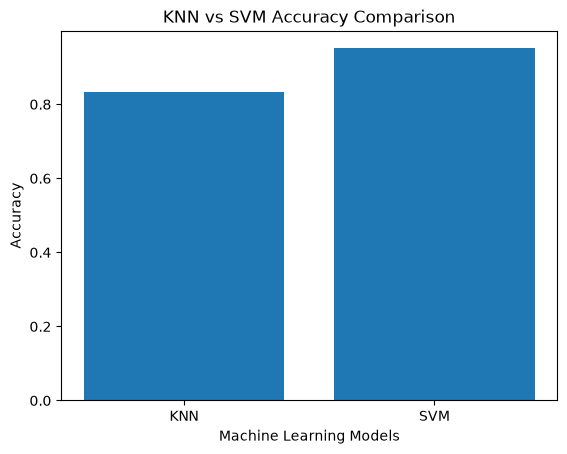

In [12]:
models = ['KNN', 'SVM']

accuracies = [
    accuracy_score(y_test, knn_predictions),
    accuracy_score(y_test, svm_predictions)
]

plt.bar(models, accuracies)

plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")
plt.title("KNN vs SVM Accuracy Comparison")

plt.show()